# PathSnap — Exploratory Data Analysis

This notebook **visualises** the Phase 0 dataset analysis. It does not recompute statistics: every table and plot is
loaded from `results/analysis/<partition>/*.csv`, produced by `python -m scripts.analysis.run_all`.

* **train** (80 trips) — used for training, cross-validation and tuning
* **student_test** (10 trips) — development-stage evaluation only
* **evaluator_test** — never opened here (leakage rule)

Every figure title names the partition it uses. All PNGs are saved to `results/eda/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "pathsnap").is_dir():      # works from repo root or notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

ANALYSIS = ROOT / "results" / "analysis"
OUT = ROOT / "results" / "eda"
OUT.mkdir(parents=True, exist_ok=True)
PARTS = ["train", "student_test"]
PCOL = {"train": "#1f77b4", "student_test": "#ff7f0e"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def load(name):
    """Concatenate one analysis CSV over both partitions, with a 'partition' column."""
    frames = []
    for p in PARTS:
        df = pd.read_csv(ANALYSIS / p / name, dtype={"trip_id": str})
        df["trip_id"] = df["trip_id"].str.zfill(8)
        df["partition"] = p
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight", dpi=150)
    print("saved", (OUT / name).relative_to(ROOT))

inv, trk, iss, gaps = load("inventory.csv"), load("tracks_summary.csv"), load("track_issues.csv"), load("track_gaps.csv")
net, rte, brk = load("network_summary.csv"), load("routes_summary.csv"), load("route_breaks.csv")
gvr, den, smp = load("gps_route_distance.csv"), load("candidate_density.csv"), load("gps_route_distance_sample.csv")
inv.groupby("partition").agg(trips=("trip_id", "count"), gps_points=("track_rows", "sum"),
                             nodes=("nodes_rows", "sum"), arcs=("arcs_rows", "sum"), route_arcs=("route_rows", "sum"))

,trips,gps_points,nodes,arcs,route_arcs
partition,,,,,
student_test,10,19160,90689,185041,3477
train,80,208417,1933485,3876904,31336


## 1. Dataset inventory — GPS points per trip

saved results/eda/01_points_per_trip.png


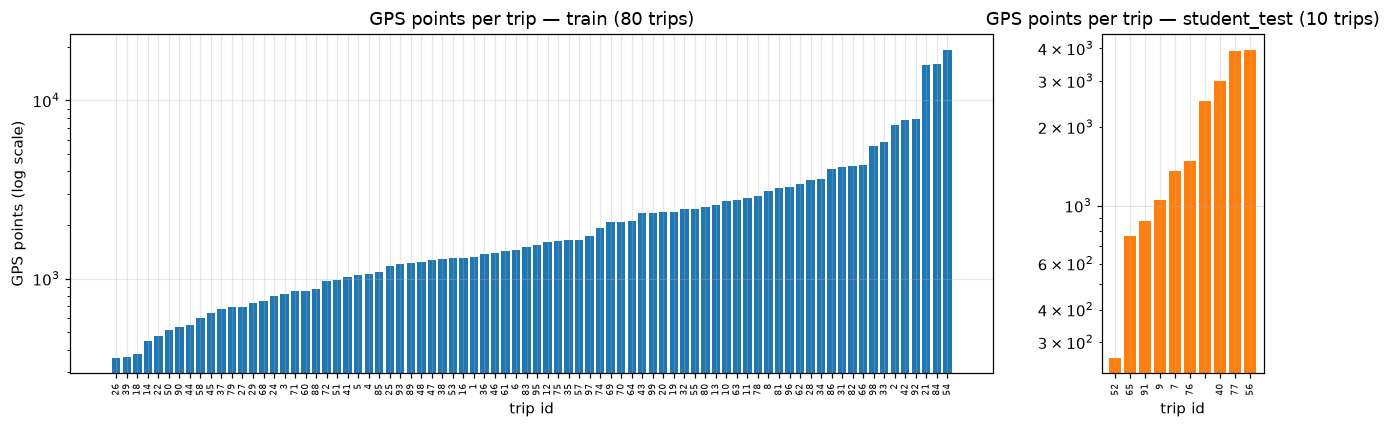

partition         student_test     train
track_rows count          10.0      80.0
           mean         1916.0    2605.0
           std          1335.0    3312.0
           min           262.0     361.0
           25%           918.0     946.0
           50%          1420.0    1529.0
           75%          2872.0    2793.0
           max          3958.0   19313.0
nodes_rows count          10.0      80.0
           mean         9069.0   24169.0
           std          7452.0   32272.0
           min          1770.0     299.0
           25%          4908.0    3488.0
           50%          6596.0    9608.0
           75%         11844.0   28847.0
           max         26635.0  155003.0
arcs_rows  count          10.0      80.0
           mean        18504.0   48461.0
           std         15497.0   64739.0
           min          3577.0     649.0
           25%         10292.0    7062.0
           50%         13145.0   19526.0
           75%         24818.0   58003.0
           max         56027.0  307392.0
route_rows count          10.0      80.0
           mean          348.0     392.0
           std           360.0     361.0
           min            95.0      59.0
           25%           154.0     168.0
           50%           250.0     280.0
           75%           358.0     480.0
           max          1323.0    2266.0

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [8, 1.4]})
for ax, p in zip(axes, PARTS):
    s = inv[inv.partition == p].sort_values("track_rows")
    ax.bar(s.trip_id.str.lstrip("0"), s.track_rows, color=PCOL[p])
    ax.set_yscale("log"); ax.set_title(f"GPS points per trip — {p} ({len(s)} trips)")
    ax.set_xlabel("trip id"); ax.tick_params(axis="x", rotation=90, labelsize=6)
axes[0].set_ylabel("GPS points (log scale)")
save(fig, "01_points_per_trip.png"); plt.show()
inv.groupby("partition")[["track_rows", "nodes_rows", "arcs_rows", "route_rows"]].describe().T.round(0)

## 2. Missing and invalid values
Counts of rows with NaN / inf, coordinates outside [-180, 180] × [-90, 90], suspected lon/lat swaps (points fit the road
network's bounding box better when swapped), duplicate rows / timestamps and non-monotonic time.

/tmp/ipykernel_107790/560613594.py:5: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  missing_files = (inv["issues"].fillna("") != "").groupby(inv.partition).sum()


saved results/eda/02_missing_invalid_table.png


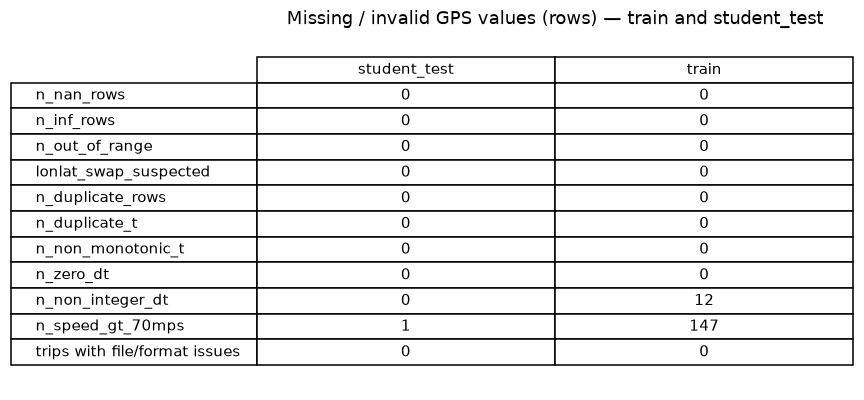

partition,student_test,train
n_nan_rows,0,0
n_inf_rows,0,0
n_out_of_range,0,0
lonlat_swap_suspected,0,0
n_duplicate_rows,0,0
n_duplicate_t,0,0
n_non_monotonic_t,0,0
n_zero_dt,0,0
n_non_integer_dt,0,12
n_speed_gt_70mps,1,147


In [3]:
cols = ["n_nan_rows", "n_inf_rows", "n_out_of_range", "lonlat_swap_suspected", "n_duplicate_rows",
        "n_duplicate_t", "n_non_monotonic_t", "n_zero_dt", "n_non_integer_dt", "n_speed_gt_70mps"]
iss["lonlat_swap_suspected"] = iss["lonlat_swap_suspected"].astype(str).eq("True").astype(int)
table = iss.groupby("partition")[cols].sum().T
missing_files = (inv["issues"].fillna("") != "").groupby(inv.partition).sum()
table.loc["trips with file/format issues"] = missing_files
fig, ax = plt.subplots(figsize=(7, 4.2)); ax.axis("off")
t = ax.table(cellText=table.values, rowLabels=table.index, colLabels=table.columns, loc="center", cellLoc="center")
t.scale(1, 1.4); ax.set_title("Missing / invalid GPS values (rows) — train and student_test")
save(fig, "02_missing_invalid_table.png"); plt.show()
table

## 3. Sampling interval and time gaps
`track_gaps.csv` lists every step with Δt > 10 s; `tracks_summary.csv` has each trip's share of steps that are exactly 1 s.

saved results/eda/03_time_gaps.png


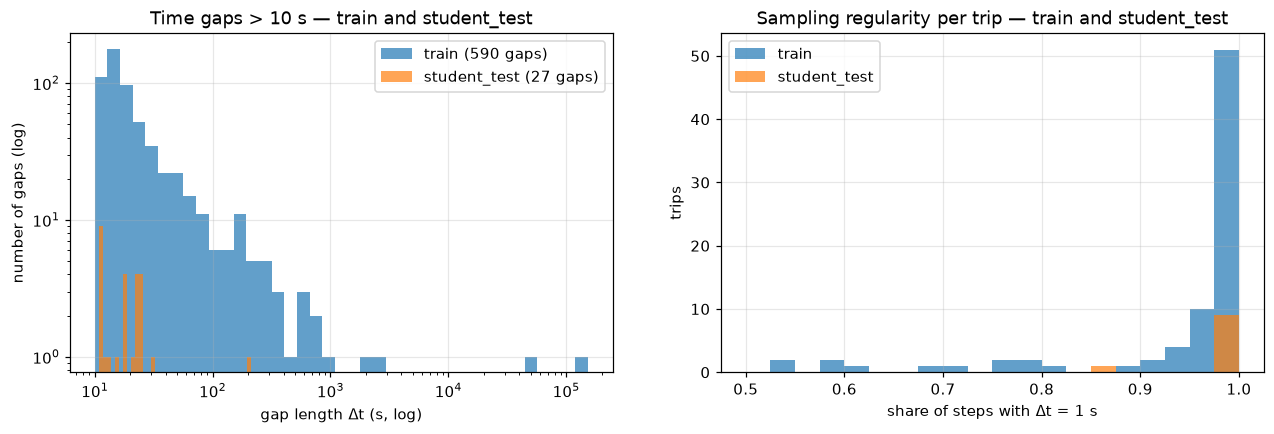

Trips with a gap > 60 s:


,partition,trip_id,n_points,n_gaps_gt_60s,n_gaps_gt_300s,dt_max
0,train,00000090,536,1,1,153064.0
1,train,00000078,2909,1,1,52810.0
2,train,00000069,2067,2,2,2658.0
3,train,00000021,15783,2,2,2161.0
4,train,00000011,2828,1,1,909.0
5,train,00000042,7739,17,4,670.0
6,train,00000081,3224,15,1,536.0
7,train,00000024,801,2,1,458.0
8,train,00000044,546,1,1,341.0
9,train,00000084,16031,2,1,312.0


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for p in PARTS:
    g = gaps[gaps.partition == p].dt_s
    if len(g):
        axes[0].hist(g, bins=np.logspace(1, np.log10(g.max() + 1), 40), color=PCOL[p], alpha=0.7, label=f"{p} ({len(g)} gaps)")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("gap length Δt (s, log)"); axes[0].set_ylabel("number of gaps (log)")
axes[0].set_title("Time gaps > 10 s — train and student_test"); axes[0].legend()
for p in PARTS:
    s = trk[trk.partition == p]
    axes[1].hist(s.dt_share_1s, bins=20, range=(0.5, 1), color=PCOL[p], alpha=0.7, label=p)
axes[1].set_xlabel("share of steps with Δt = 1 s"); axes[1].set_ylabel("trips")
axes[1].set_title("Sampling regularity per trip — train and student_test"); axes[1].legend()
save(fig, "03_time_gaps.png"); plt.show()
print("Trips with a gap > 60 s:")
trk[trk.n_gaps_gt_60s > 0][["partition", "trip_id", "n_points", "n_gaps_gt_60s", "n_gaps_gt_300s", "dt_max"]] \
    .sort_values("dt_max", ascending=False).reset_index(drop=True)

## 4. Geographical extent — where are the trips and how long are they?

saved results/eda/04_extent_world_and_length.png


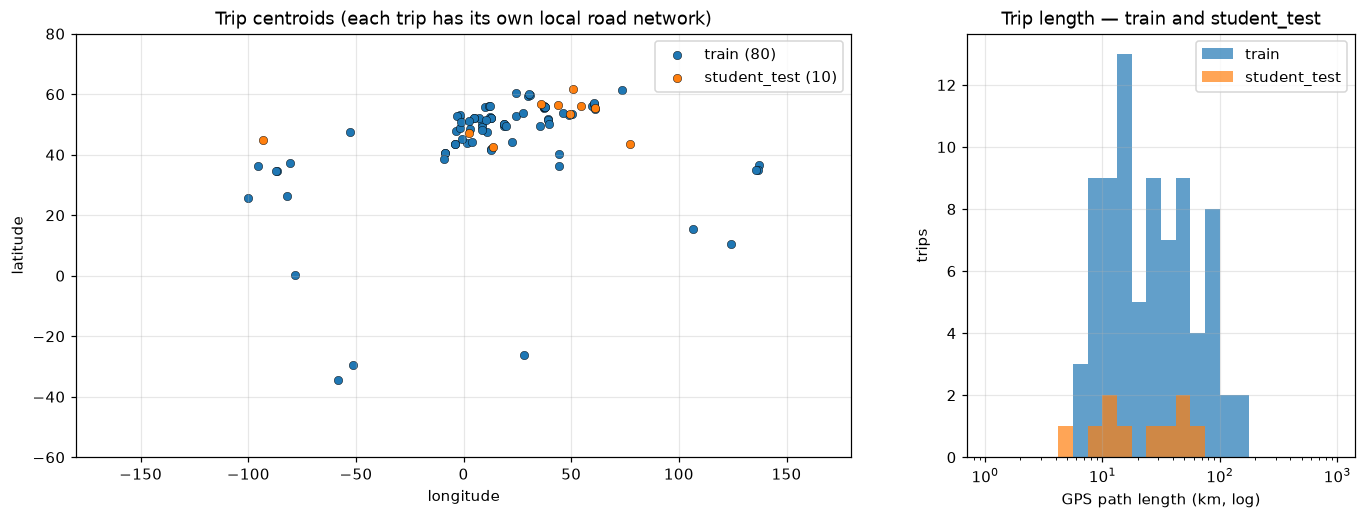

saved results/eda/04_trip_centroids_map.html


partition            student_test     train
n_points      count          10.0      80.0
              mean         1916.0    2605.2
              std          1335.4    3312.3
              min           262.0     361.0
              25%           917.8     945.8
              50%          1420.0    1529.0
              75%          2872.0    2792.8
              max          3958.0   19313.0
duration_s    count          10.0      80.0
              mean         2025.0    5680.4
              std          1311.7   18252.2
              min           265.0     451.0
              25%          1040.0    1225.3
              50%          1809.5    1710.0
              75%          2871.2    3765.0
              max          4000.0  154030.0
path_length_m count          10.0      80.0
              mean        29696.8   37230.2
              std         22830.1   34501.9
              min          5546.8    6334.2
              25%         12171.7   12777.5
              50%         20935.6   24065.7
              75%         48393.4   48714.7
              max         71715.9  169254.0
extent_x_km   count          10.0      80.0
              mean            9.9      14.1
              std            12.9      16.3
              min             2.2       0.9
              25%             3.2       3.3
              50%             5.3       7.6
              75%            10.4      17.1
              max            45.0      70.9
extent_y_km   count          10.0      80.0
              mean            9.1      11.9
              std             8.0      14.6
              min             1.8       0.9
              25%             3.8       3.3
              50%             5.9       5.3
              75%            11.6      14.0
              max            27.1      75.1
speed_p50_mps count          10.0      80.0
              mean           15.2      14.8
              std             4.7       7.6
              min             8.5       5.6
              25%            12.1       9.8
              50%            15.0      12.7
              75%            18.0      17.1
              max            22.0      41.3

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})
for p in PARTS:
    s = trk[trk.partition == p]
    axes[0].scatter(s.centroid_lon, s.centroid_lat, s=30, color=PCOL[p], label=f"{p} ({len(s)})", edgecolor="k", lw=0.3)
axes[0].set_xlim(-180, 180); axes[0].set_ylim(-60, 80)
axes[0].set_xlabel("longitude"); axes[0].set_ylabel("latitude")
axes[0].set_title("Trip centroids (each trip has its own local road network)"); axes[0].legend()
for p in PARTS:
    s = trk[trk.partition == p]
    axes[1].hist(s.path_length_m / 1000, bins=np.logspace(0, 3, 25), color=PCOL[p], alpha=0.7, label=p)
axes[1].set_xscale("log"); axes[1].set_xlabel("GPS path length (km, log)"); axes[1].set_ylabel("trips")
axes[1].set_title("Trip length — train and student_test"); axes[1].legend()
save(fig, "04_extent_world_and_length.png"); plt.show()

import folium
wm = folium.Map(location=[30, 10], zoom_start=2, tiles="OpenStreetMap")
for p in PARTS:
    for r in trk[trk.partition == p].itertuples():
        folium.CircleMarker([r.centroid_lat, r.centroid_lon], radius=5, color=PCOL[p], fill=True, fill_opacity=0.8,
                            tooltip=f"{p} trip {r.trip_id}: {r.n_points} pts, {r.path_length_m/1000:.1f} km").add_to(wm)
wm.save(str(OUT / "04_trip_centroids_map.html")); print("saved results/eda/04_trip_centroids_map.html")
trk.groupby("partition")[["n_points", "duration_s", "path_length_m", "extent_x_km", "extent_y_km", "speed_p50_mps"]].describe().T.round(1)

## 5. Road networks — size, two-way roads and connectivity

saved results/eda/05_network_size_two_way.png


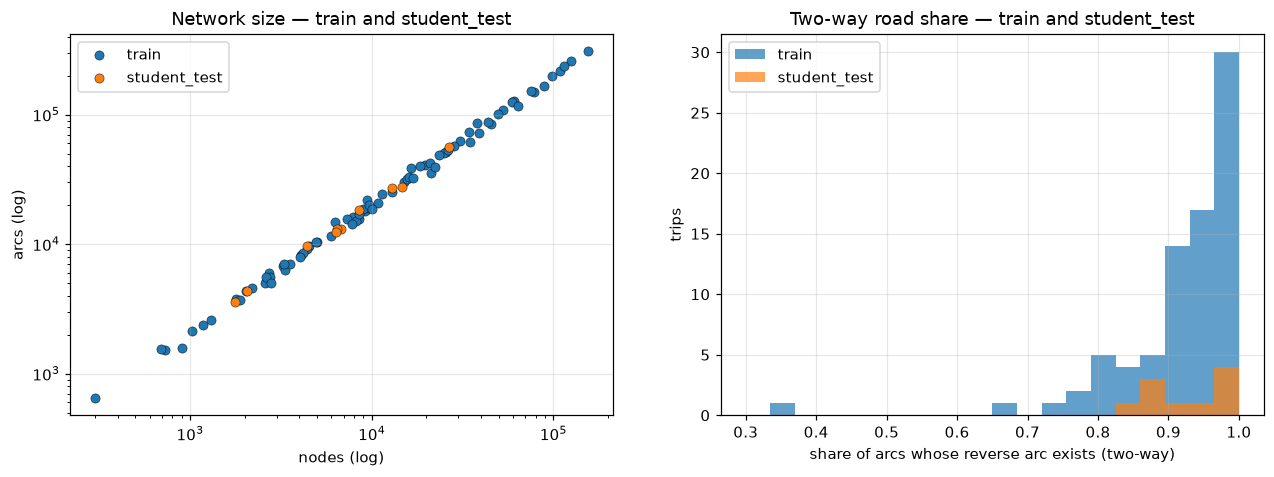

partition                student_test    train
n_weak_components count        10.000   80.000
                  mean         22.700   39.012
                  std          29.182   60.682
                  min           5.000    1.000
                  25%           7.250    9.750
...                               ...      ...
n_duplicate_arcs  min           0.000    0.000
                  25%           0.500    0.000
                  50%           3.500    2.000
                  75%          18.000   12.000
                  max          62.000  322.000

[64 rows x 2 columns]

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for p in PARTS:
    s = net[net.partition == p]
    axes[0].scatter(s.n_nodes, s.n_arcs, color=PCOL[p], label=p, edgecolor="k", lw=0.3)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("nodes (log)"); axes[0].set_ylabel("arcs (log)"); axes[0].set_title("Network size — train and student_test")
axes[0].legend()
for p in PARTS:
    axes[1].hist(net[net.partition == p].two_way_share, bins=20, range=(0.3, 1), color=PCOL[p], alpha=0.7, label=p)
axes[1].set_xlabel("share of arcs whose reverse arc exists (two-way)"); axes[1].set_ylabel("trips")
axes[1].set_title("Two-way road share — train and student_test"); axes[1].legend()
save(fig, "05_network_size_two_way.png"); plt.show()
net.groupby("partition")[["n_weak_components", "n_strong_components", "largest_weak_share", "largest_strong_share",
                          "n_isolated_nodes", "n_dead_end_nodes", "n_self_loops", "n_duplicate_arcs"]].describe().T.round(3)

## 6. Reference routes — continuity

saved results/eda/06_route_continuity.png


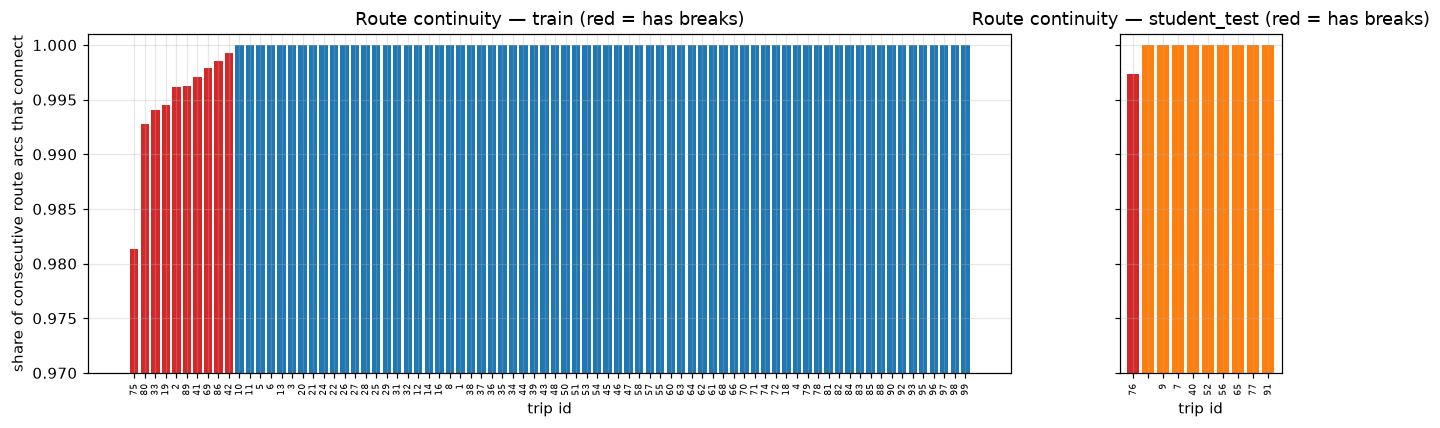

,partition,trip_id,route_pos,arc_before,arc_after,gap_m
3,train,00000019,300,953,23709,595.814100
0,train,00000002,53,1848,10863,324.678998
2,train,00000019,151,55059,55050,255.186414
1,train,00000019,94,85589,51027,241.017689
10,train,00000080,118,8899,9194,107.822218
11,train,00000086,1,230068,96025,97.741141
4,train,00000033,164,1003,1002,91.934327
9,train,00000075,62,134,552,73.045175
5,train,00000041,12,1264,519,57.227432
7,train,00000069,153,10165,10172,40.859985


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [8, 1.4]}, sharey=True)
for ax, p in zip(axes, PARTS):
    s = rte[rte.partition == p].sort_values("continuity")
    ax.bar(s.trip_id.str.lstrip("0"), s.continuity, color=np.where(s.n_breaks > 0, "#d62728", PCOL[p]))
    ax.set_ylim(0.97, 1.001); ax.set_title(f"Route continuity — {p} (red = has breaks)")
    ax.tick_params(axis="x", rotation=90, labelsize=6); ax.set_xlabel("trip id")
axes[0].set_ylabel("share of consecutive route arcs that connect")
save(fig, "06_route_continuity.png"); plt.show()
brk[["partition", "trip_id", "route_pos", "arc_before", "arc_after", "gap_m"]].sort_values("gap_m", ascending=False)

## 7. GPS noise relative to the reference route, and candidate density
Distance of each sampled GPS point (every 5th) to the nearest reference-route arc, and how many arcs fall within a
radius R (candidates) versus how often the route is inside R (coverage = 1 − candidate miss rate).

saved results/eda/07_gps_route_distance_and_candidates.png


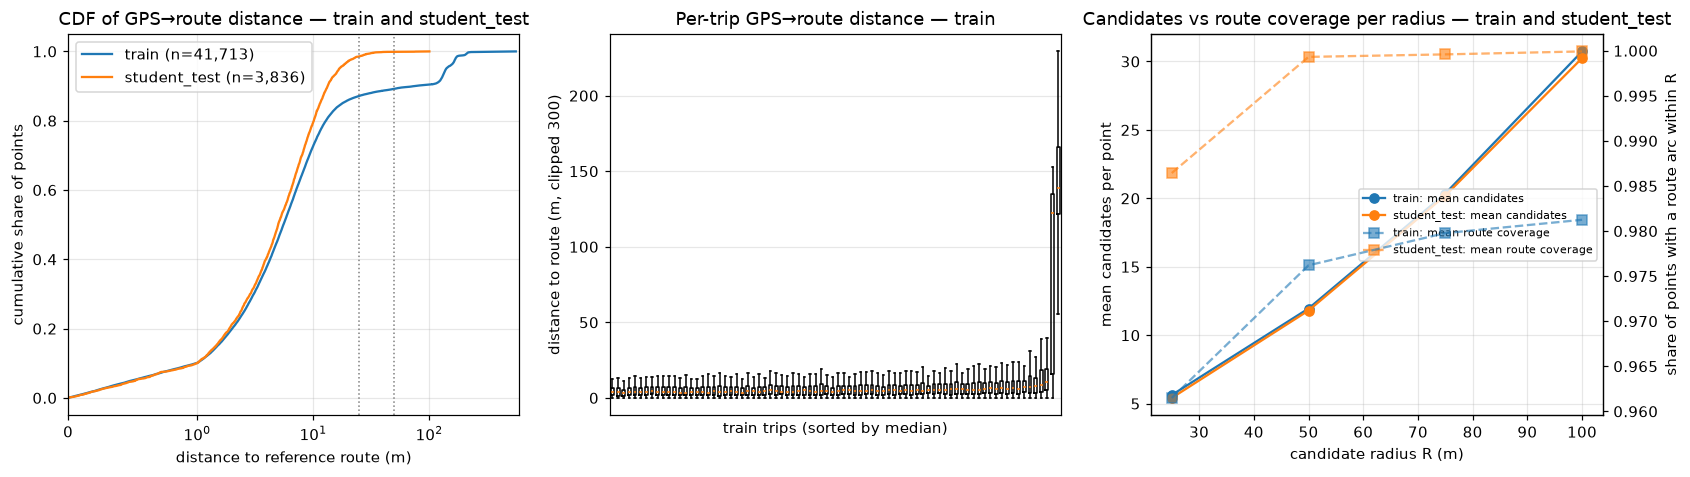

,partition,radius_m,cand,cov,cov_q10
0,student_test,25,5.418,0.986,0.976
1,student_test,50,11.803,0.999,0.999
2,student_test,75,20.202,1.000,1.000
3,student_test,100,30.245,1.000,1.000
4,train,25,5.629,0.961,0.929
5,train,50,11.951,0.976,0.982
6,train,75,20.351,0.980,0.989
7,train,100,30.736,0.981,0.997


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for p in PARTS:
    d = np.sort(smp[smp.partition == p].d_route_m.dropna().to_numpy())
    axes[0].plot(d, np.arange(1, len(d) + 1) / len(d), color=PCOL[p], label=f"{p} (n={len(d):,})")
axes[0].set_xscale("symlog", linthresh=1); axes[0].set_xlim(0, 600)
for x in (25, 50): axes[0].axvline(x, color="grey", ls=":", lw=1)
axes[0].set_xlabel("distance to reference route (m)"); axes[0].set_ylabel("cumulative share of points")
axes[0].set_title("CDF of GPS→route distance — train and student_test"); axes[0].legend()

order = gvr[gvr.partition == "train"].sort_values("d_route_p50_m").trip_id
data = [smp[(smp.partition == "train") & (smp.trip_id == t)].d_route_m.clip(upper=300) for t in order]
axes[1].boxplot(data, showfliers=False); axes[1].set_xticks([])
axes[1].set_xlabel("train trips (sorted by median)"); axes[1].set_ylabel("distance to route (m, clipped 300)")
axes[1].set_title("Per-trip GPS→route distance — train")

agg = den.groupby(["partition", "radius_m"]).agg(cand=("cand_mean", "mean"), cov=("route_within_radius_share", "mean"),
                                                cov_q10=("route_within_radius_share", lambda s: s.quantile(.1))).reset_index()
ax2 = axes[2].twinx()
for p in PARTS:
    a = agg[agg.partition == p]
    axes[2].plot(a.radius_m, a.cand, "o-", color=PCOL[p], label=f"{p}: mean candidates")
    ax2.plot(a.radius_m, a["cov"], "s--", color=PCOL[p], alpha=0.6, label=f"{p}: mean route coverage")
axes[2].set_xlabel("candidate radius R (m)"); axes[2].set_ylabel("mean candidates per point")
ax2.set_ylabel("share of points with a route arc within R"); ax2.grid(False)
axes[2].set_title("Candidates vs route coverage per radius — train and student_test")
h1, l1 = axes[2].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[2].legend(h1 + h2, l1 + l2, fontsize=7, loc="center right")
save(fig, "07_gps_route_distance_and_candidates.png"); plt.show()
agg.round(3)

### Trips with many far-off points
Trips where > 5 % of points are > 50 m from the reference route. `far_spread_m` (extent of those points) and
`far_time_share` separate **off-network dwell** (compact cluster, long time — e.g. parked) from **route mismatch**.

In [9]:
gvr[gvr.share_d_route_gt_50m > 0.05][["partition", "trip_id", "n_points", "d_route_p50_m", "share_d_route_gt_50m",
                                       "far_spread_m", "far_time_share", "nearest_arc_on_route_share"]].round(3)

,partition,trip_id,n_points,d_route_p50_m,share_d_route_gt_50m,far_spread_m,far_time_share,nearest_arc_on_route_share
1,train,00000002,7243,5.674,0.120,3605.496,0.110,0.852
26,train,00000033,5844,122.413,0.589,1053.210,0.596,0.267
35,train,00000043,2322,10.985,0.072,21050.605,0.063,0.642
44,train,00000054,19313,138.588,0.872,1121.996,0.872,0.097


## 8. Trajectory and nearby road network — four representative trips (train)
Chosen automatically by `scripts/make_maps.py --pick4`: shortest, longest clean trip, most gaps > 60 s, densest network.
The interactive versions are in `results/maps/<trip>.html`. Colour = distance to the reference route.

In [10]:
from pathsnap.io import load_trip
from pathsnap.viz import prepare, static_png
from scripts.make_maps import pick_representative

picks = pick_representative("train")
print(picks)
for label, tid in picks.items():
    trip = load_trip(tid, "train")
    path = OUT / f"08_trajectory_{label}_{tid}.png"
    static_png(trip, prepare(trip), path)
    print("saved", path.relative_to(ROOT))

{'short': '00000018', 'long': '00000084', 'gaps': '00000042', 'dense_network': '00000013'}


saved results/eda/08_trajectory_short_00000018.png


saved results/eda/08_trajectory_long_00000084.png


saved results/eda/08_trajectory_gaps_00000042.png


saved results/eda/08_trajectory_dense_network_00000013.png


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for ax, (label, tid) in zip(axes.ravel(), picks.items()):
    ax.imshow(plt.imread(OUT / f"08_trajectory_{label}_{tid}.png")); ax.axis("off")
    ax.set_title(f"{label}: trip {tid} (train)")
plt.tight_layout(); plt.show()

/tmp/ipykernel_107790/1524050334.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## 9. Summary of findings
The written findings and the decisions they drive are in `results/eda/data_quality.md`; the numeric report is
`results/analysis/<partition>/DATASET_REPORT.md`.

In [12]:
print((ROOT / "results" / "eda" / "data_quality.md").read_text()[:3000])

# Data quality findings and decisions

Source: `results/analysis/<partition>/*.csv` (Phase 0 scripts) visualised in `notebooks/01_eda.ipynb`.
Partition is stated for every finding. evaluator_test was not opened.

## Organisation of the raw data
- One folder per trip with four header-less, whitespace-separated files: `.track` (lon, lat, t), `.nodes` (lon, lat),
  `.arcs` (from_node, to_node) and `.route` (ordered arc ids). Node id = row index in `.nodes`; arc id = row index in `.arcs`.
- **Each trip has its own local road network**, so node/arc ids only mean something inside that trip.
- All 80 train and 10 student_test trips have all four files; no parse or column-count errors.
- `.route` lists the arcs driven, in order, but **does not say which GPS point is on which arc**. Per-point labels must be
  derived by aligning the GPS sequence to the route (Phase 2).

## GPS tracks
- train: 208,417 points; student_test: 19,160 points. Trips range from 262 to 19,313 points.
- No NaN/inf values